In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from langchain_core.messages import AIMessage,HumanMessage,SystemMessage

In [2]:
if os.environ.get("OPENAI_API_KEY"):
    api_key = os.environ.get("OPENAI_API_KEY")
    print("API Key is all set!!")
else:
    raise ValueError("API Key not present!!")

API Key is all set!!


In [3]:
llm = init_chat_model("gpt-5-nano",temperature = 0)


In [4]:
from pydantic import BaseModel,Field


class graph_schema(BaseModel):
    topic:str = Field(description="Enter the given topic")
    post:str = Field(description="Enter an linkedin post")
    curated_post:str = Field(description="This is a curated post")

demo_proj = graph_schema(
    topic = "databricks",
    post= "Write a post about databricks ",
    curated_post  = "this is a curated post about databricks"
)



In [5]:
def create_post(state:graph_schema)->graph_schema:
    state = state.model_dump()
    topic = state['topic']
    post = llm.invoke(f"write a linkedin post about {topic}").content
    state['post'] = post
    return state

def curated_post(state:graph_schema)->graph_schema:
    state = state.model_dump()
    topic = state['topic']
    curated_post = llm.invoke(f"this is a curated post about {topic}")
    state['curated_post'] = curated_post
    return state



In [6]:
# from langgraph.graph import StateGraph,START,END

# graph = StateGraph(graph_schema)

# graph.add_node("create_post",create_post)
# graph.add_node("curated_post",curated_post)

# graph.add_edge(START,"create_post")
# graph.add_edge("create_post","curated_post")
# graph.add_edge("curated_post",END)

In [9]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node("curated_post",curated_post)

graph.add_edge(START,"create_post")
graph.add_edge(START,"curated_post")
graph.add_edge("create_post",END)
graph.add_edge("curated_post",END)


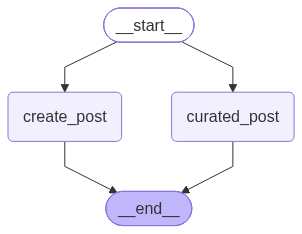

In [10]:
from IPython.display import Image,display

pydantic_graph = graph.compile()

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [ ]:
pydantic_graph.invoke({"topic":"databricks",
              "post":"",
              "curated_post":""})

{'topic': 'databricks',
 'post': 'Here are a few LinkedIn post options you can use or adapt. Each has a different tone and length:\n\nOption 1 — Short and punchy (about 90 words)\n- Databricks is shaping how teams turn data into decisions. The Lakehouse Platform unifies data engineering, data science, and AI on a single collaborative platform—built on Apache Spark with Delta Lake for reliable storage and Unity Catalog for governance. By reducing data silos and data prep friction, organizations can move from analytics to AI faster. If your stack is ready to scale data analytics and responsible AI, it’s worth a closer look at Databricks.\n- Hashtags: #Databricks #Lakehouse #DataEngineering #DataScience #AI #DeltaLake\n\nOption 2 — Narrative/insight (about 180-220 words)\n- Over the past year, many teams have found Databricks Lakehouse Platform to be a turning point for data work. By unifying data engineering, analytics, and ML on one platform—built on Apache Spark and powered by Delta La